In [3]:
import matplotlib.pyplot as plt
import pandas as pd
from kneed import KneeLocator
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler


In [4]:
df = pd.read_csv("C:/Sarang/College/lp3/ml/sales_data_sample.csv", encoding="ISO-8859-1")

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

First 5 rows:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye

In [5]:
features = [
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES",
    "MSRP"
]

X = df[features].copy()

print("\nSelected features:")
print(X.head())


Selected features:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP
0               30      95.70  2871.00    95
1               34      81.35  2765.90    95
2               41      94.74  3884.34    95
3               45      83.26  3746.70    95
4               49     100.00  5205.27    95


In [6]:
print("\nMissing values:")
print(X.isnull().sum())

X = X.dropna()


Missing values:
QUANTITYORDERED    0
PRICEEACH          0
SALES              0
MSRP               0
dtype: int64


In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [8]:
inertia = []

K = range(1, 11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia.append(kmeans.inertia_)

In [9]:
kl = KneeLocator(
    K,
    inertia,
    curve="convex",
    direction="decreasing"
)

optimal_k = kl.elbow

print("\nOptimal number of clusters:", optimal_k)


Optimal number of clusters: 3


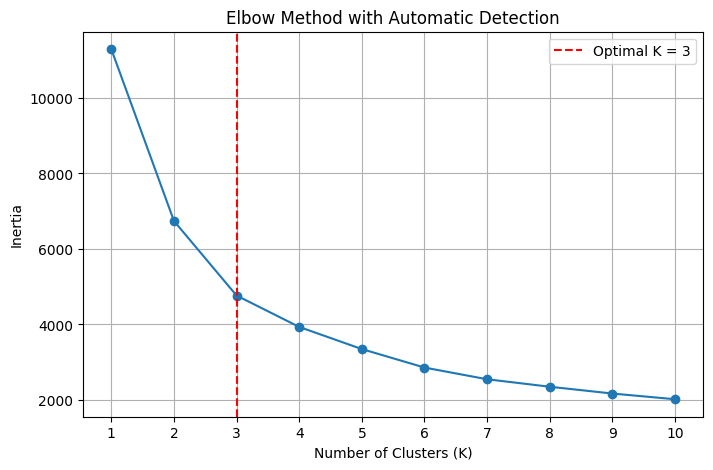

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    K,
    inertia,
    marker="o"
)

if optimal_k is not None:
    plt.axvline(
        x=optimal_k,
        color="red",
        linestyle="--",
        label=f"Optimal K = {optimal_k}"
    )

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method with Automatic Detection")

plt.xticks(K)
plt.grid(True)
plt.legend()

plt.show()

In [11]:
if optimal_k is None:
    raise ValueError("Elbow point could not be detected.")

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

In [12]:
X["Cluster"] = clusters

print("\nClustered data:")
print(X.head(10))


Clustered data:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP  Cluster
0               30      95.70  2871.00    95        2
1               34      81.35  2765.90    95        2
2               41      94.74  3884.34    95        1
3               45      83.26  3746.70    95        1
4               49     100.00  5205.27    95        1
5               36      96.66  3479.76    95        2
6               29      86.13  2497.77    95        2
7               48     100.00  5512.32    95        1
8               22      98.57  2168.54    95        2
9               41     100.00  4708.44    95        1


In [13]:
print("\nNumber of records in each cluster:")
print(X["Cluster"].value_counts().sort_index())


Number of records in each cluster:
Cluster
0    975
1    852
2    996
Name: count, dtype: int64


In [14]:
centers = scaler.inverse_transform(kmeans.cluster_centers_)

cluster_centers = pd.DataFrame(
    centers,
    columns=features
)

print("\nCluster Centers:")
print(cluster_centers)


Cluster Centers:
   QUANTITYORDERED  PRICEEACH        SALES        MSRP
0        35.208205  59.551169  2101.076482   64.145641
1        43.726204  97.485229  5722.350564  127.952996
2        27.610832  95.432046  3123.730140  113.229689


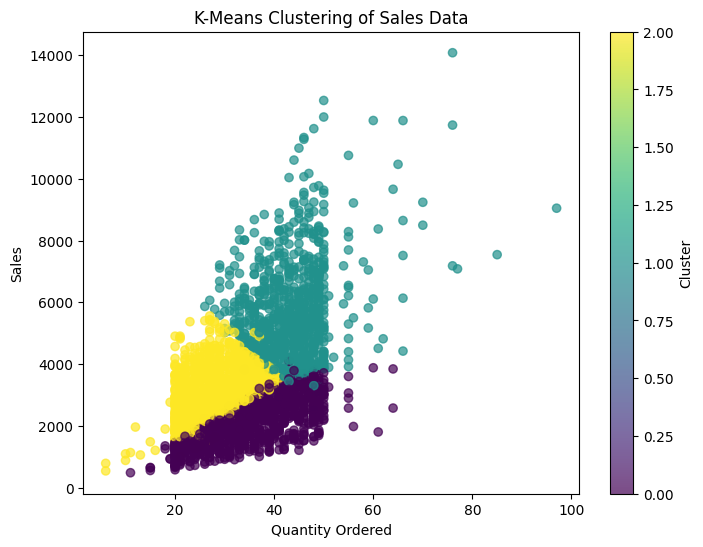

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X["QUANTITYORDERED"],
    X["SALES"],
    c=X["Cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("K-Means Clustering of Sales Data")
plt.colorbar(label="Cluster")

plt.show()